# control de eventos con guardas: Comparación con métodos publicados

**Nivel:** 3 **Requisitos previos:** Control rápido por eventos nivel 1 **Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Cómo se compara una nueva ejecución de la mejor referencia aprendida con las políticas rápidas protegidas en esta observación C01 emparejada?

## Objetivos

Esta lección investiga la pregunta: ¿Cómo se compara una nueva ejecución de la mejor referencia aprendida con las políticas rápidas protegidas en esta observación C01 emparejada?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2 ```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/episodes/M01-C01-nominal-40000; - `data/derived/episodes/M02-C01-nominal-40000; json`

## Método

La comparación se sitúa frente a decisiones rápidas tipadas, arbitraje entre control model-free y model-based y agentes asíncronos que combinan código y modelos de lenguaje. Estas fuentes establecen diseños previos y preguntas experimentales, no evidencia independiente de que Neuraxis sea un Sistema Uno biológico ni de que un broker tipado sea novedoso. La referencia empírica aquí es M04 en el mismo caso, mientras M01 sigue siendo la regla medida más fuerte del núcleo. Se distingue deliberadamente el arte previo de un ganador interno del benchmark. Una prueba de estrés relevante cambia el tiempo del evento o la disponibilidad de candidatos sin alterar el contrato, y verifica la poscondición en vez de comparar solo la primera acción. Lee la traza como observación, conjunto admisible, acción elegida y resultado de un oráculo independiente; unir esos campos en una sola etiqueta de éxito oculta el origen de la autoridad. La coincidencia en un caso solo demuestra consistencia local; la robustez requiere semillas y perturbaciones independientes que revelen estados obsoletos, candidatos ausentes y efectos no autorizados. Una extensión útil cambia un orden de eventos por vez, conserva el oráculo del caso y registra qué transición produjo la divergencia para reproducir la respuesta.

### control de eventos con guardas · nivel 3 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M01', 'M02', 'M04']
sample_case, seed = 'C01', 40000
evidence = load_lesson_evidence(
    ROOT, topic='01-fast-event-control', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 3 | case variants: 18


### Comparar métodos entre variantes: control de eventos con guardas

Entre variantes, distingue una respuesta admisible y rápida de una preferencia de política; una acción barata pero obsoleta sigue siendo inválida.

### control de eventos con guardas · nivel 3 | Ejecuta las políticas publicadas y compara la corrida

### control de eventos con guardas · nivel 3 | Compara la secuencia completa y no solo la primera acción

### control de eventos con guardas · nivel 3 | Recalcula resultados por variante desde todas las trazas del caso

In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "éxitos=",
        sum(values),
        "episodios=",
        len(values),
        "tasa=",
        round(sum(values) / len(values), 3),
    )


M01 boundary éxitos= 10 episodios= 10 tasa= 1.0
M01 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M01 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M01 nominal éxitos= 10 episodios= 10 tasa= 1.0
M01 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M01 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M02 boundary éxitos= 10 episodios= 10 tasa= 1.0
M02 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M02 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M02 nominal éxitos= 10 episodios= 10 tasa= 1.0
M02 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M02 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M04 boundary éxitos= 10 episodios= 10 tasa= 1.0
M04 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M04 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M04 nominal éxitos= 10 episodios= 10 tasa= 1.0
M04 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M04 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0


### control de eventos con guardas · nivel 3 | Visualiza el estrés por variante sin mezclar familias

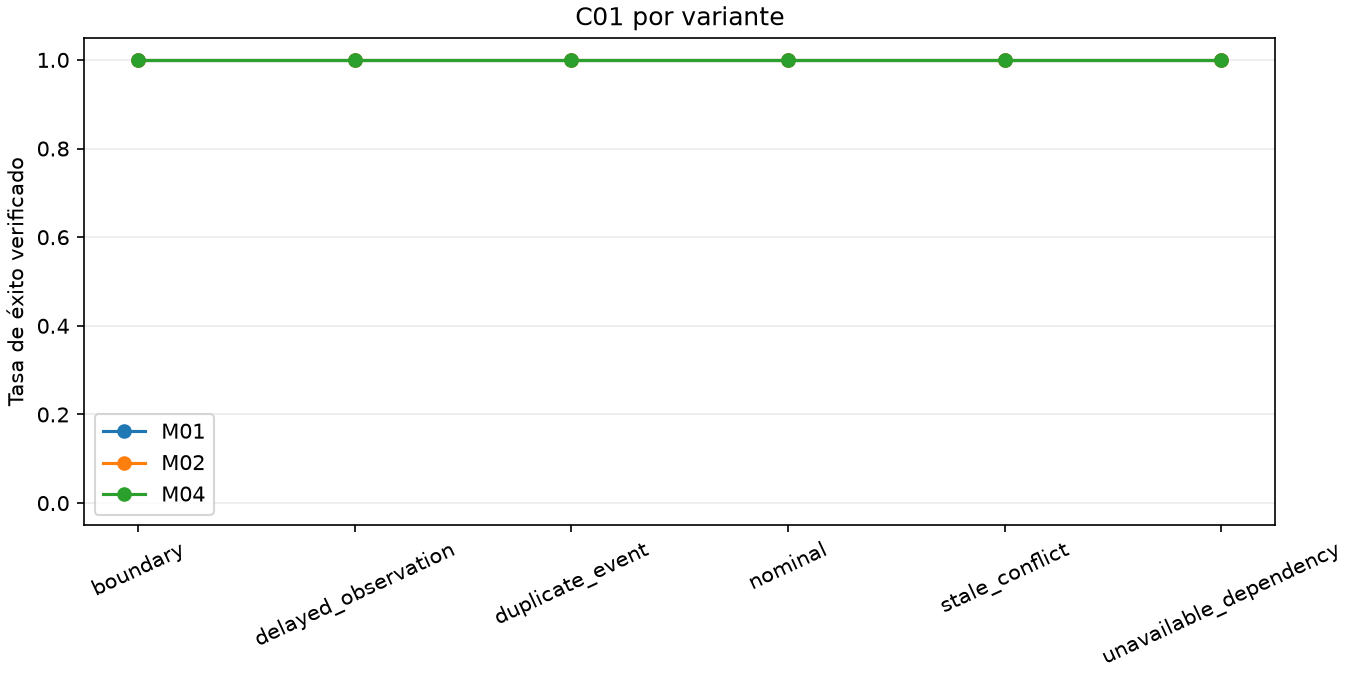

In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Compara resultados emparejados y latencia:

El gráfico 1, nivel 3, resume admisión por guardas y finalización verificada para C01. El gráfico 1 ubica admisión por guardas y finalización verificada en la familia diseñada C01 de nivel 3; Interpreta admisión por guardas y finalización verificada en el gráfico 1 para C01 con su traza y poscondición antes de llamarlo mejora del control.

In [5]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = 'M01'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M01


### control de eventos con guardas · L3 | Ejecutar el método principal en el caso indicado

De control de eventos con guardas, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida

In [6]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### control de eventos con guardas · L3 | Construir una política de comparación independiente

Crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación

In [7]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = 'M02'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M02


### control de eventos con guardas · L3 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M02 en el mismo C01, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [8]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### control de eventos con guardas · L3 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de control de eventos con guardas, y las afirmaciones entre familias aún requieren el benchmark completo

In [9]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### control de eventos con guardas · L3 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de control de eventos con guardas recién ejecutados en C01, no se copia de un artefacto congelado

## Comparación
La comparación se sitúa frente a decisiones rápidas tipadas, arbitraje entre control model-free y model-based y agentes asíncronos que combinan código y modelos de lenguaje.

### control de eventos con guardas · L3 | Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para control de eventos con guardas ejecuta M04 en C01 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.

In [10]:
# Ejecuta la política XGBoost medida con la misma especificación del caso.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Ejecuciones del método de referencia:", 1)
print("Éxito de tarea de XGBoost:", state_art_result["metrics"]["task_success"])


Ejecuciones del método de referencia: 1
Éxito de tarea de XGBoost: 1


### control de eventos con guardas · L3 | Tiempo registrado del controlador

la figura de tiempos de control de eventos con guardas usa registros congelados y verificados por hash para M01 y M04 en C01, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 3 para control de eventos con guardas describe el entorno registrado bajo su caso, variante y semilla declarados.

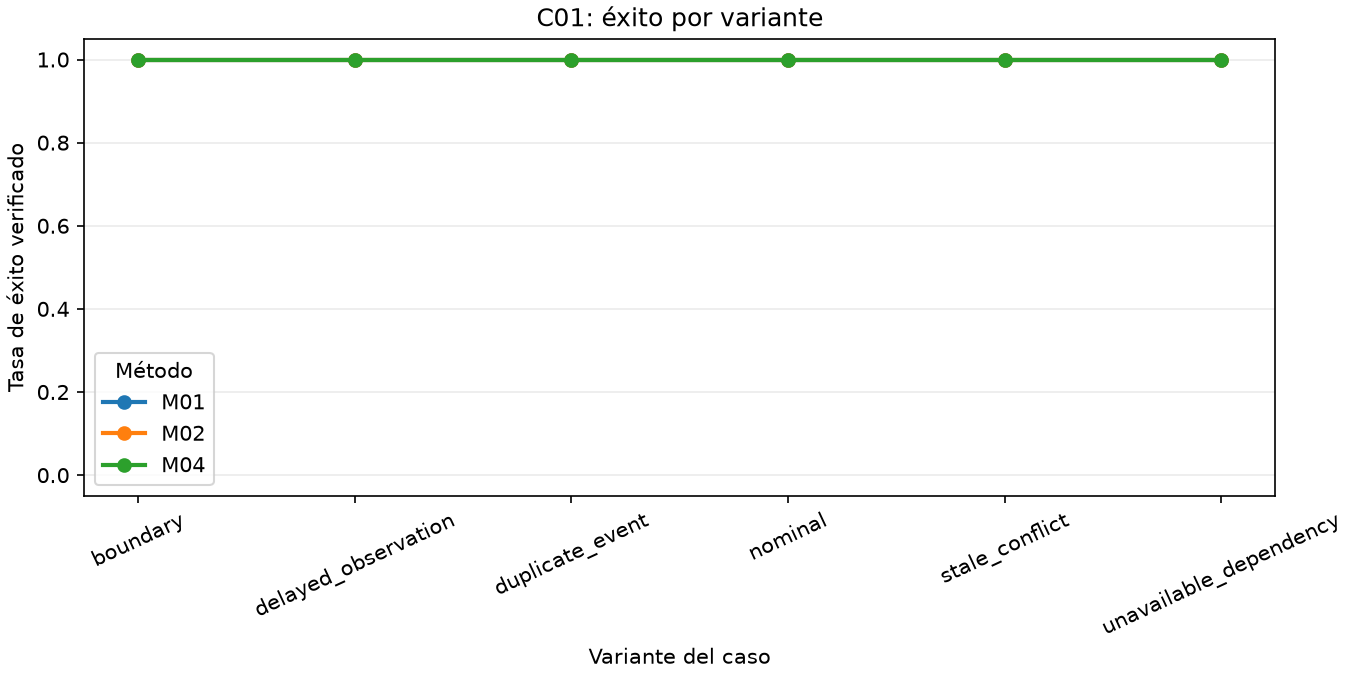

In [11]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para control de eventos con guardas, estas barras muestran resultados nuevos de poscondición de M01 y M02 en C01; Éxito vale 1 y falla 0; Lee el caso y la semilla antes de compararlas. En la comparación emparejada de control de eventos con guardas para C01, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

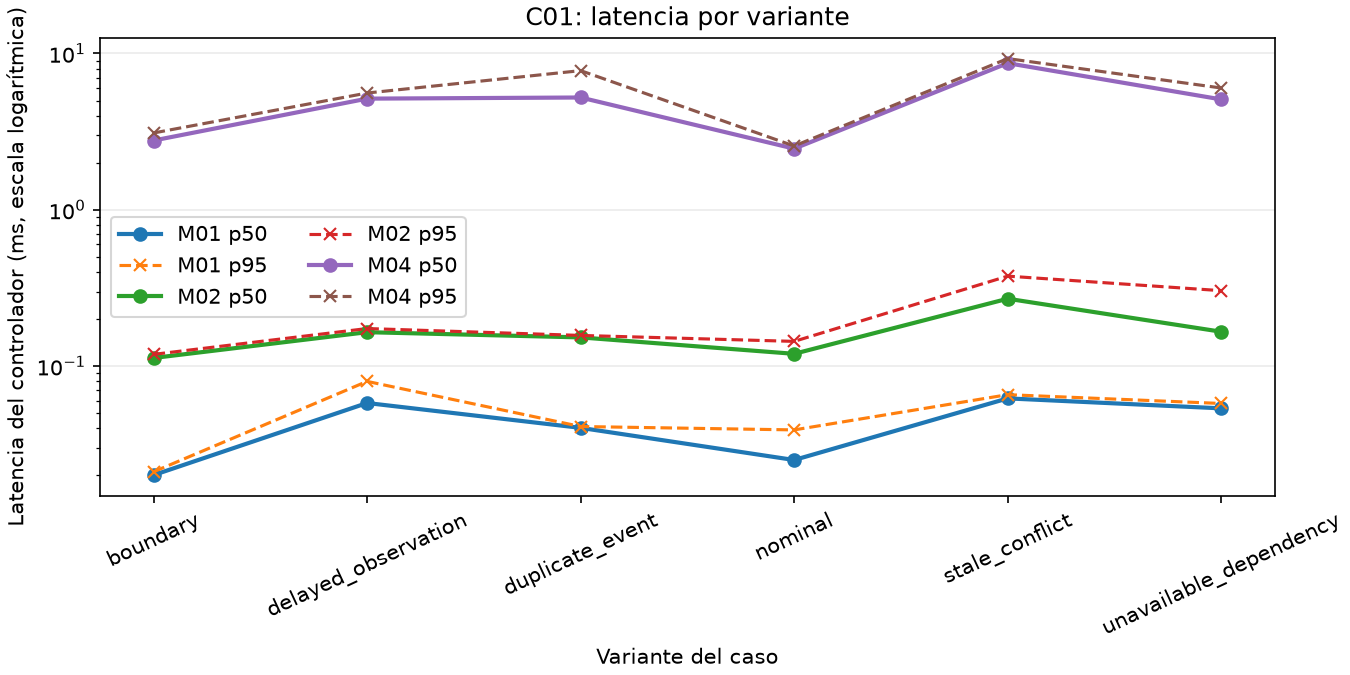

In [12]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Latencia del controlador (ms, escala logarítmica)")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": latencia por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para control de eventos con guardas lee registros canónicos de M01/M04 en C01, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. Compara resultados emparejados y latencia:

El gráfico 3, nivel 3, resume percentiles de decisión entre variantes de eventos para C01.

## Resultados

**Respuesta:** La comparación de nivel 3 para control de eventos con guardas contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C01; esas 3 corridas emparejadas no establecen superioridad poblacional para control de eventos con guardas.

Dentro de esta comparación de control de eventos con guardas (C01), esta repetición con el paquete comprueba una decisión protegida exacta sobre la misma observación congelada; En la comparación emparejada de control de eventos con guardas para C01, no demuestra transferencia general, un mecanismo biológico ni superioridad frente a un sistema desplegado y emparejado;

En la comparación emparejada de control de eventos con guardas para C01, este paso de autoría no compromete salidas generadas;

## Resumen

Compara admisibilidad y estado terminal antes de equiparar tasas de finalización.




## Referencias
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [LEE](https://doi; org/10.1016/j.neuron.2013.11.028) - [DPT](https://aclanthology.org/2025.acl-long.206/)